# Laser eyewear OD simulator: hazard distance and protective optical density

> **Educational only.** This is not a laser-safety determination. Real decisions use the
> current ANSI Z136.1 / IEC 60825-1 edition in full and a Laser Safety Officer. The MPE here is
> the simplified visible-light rule (400–700 nm, 1.8×10⁻⁵ s ≤ t ≤ 10 s) only.

**Public-safety question:** how far away can a laser pointer still injure an eye, and what
eyewear stops a lab beam? Plain Python + Jupyter, so it runs the same on Windows and macOS.
Module: `dgs/laser_eyewear.py` (tests: `tests/test_laser_eyewear.py`).

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import laser_eyewear as S
pd.set_option("display.width", 200)
MPE_BLINK = S.mpe_visible(S.BLINK_S)
print(f"visible MPE at the 0.25 s blink time: {MPE_BLINK * 1e3:.3f} mW/cm^2")

visible MPE at the 0.25 s blink time: 2.546 mW/cm^2


## 1. PHYS 106: the beam as photons

**Quantity:** photon rate N/t. **Equation:** P = (N/t)·hc/λ. **Isolated:** N/t = Pλ/(hc).
**Units:** W ÷ J = 1/s. **Meaning:** a 5 mW green pointer emits more than 10¹⁶ photons per
second, so the eye responds to the total energy delivered, not to individual photons.

In [2]:
for P_mw, lam in [(1, 532), (5, 532), (5, 650), (100, 445)]:
    print(f"{P_mw:4d} mW at {lam} nm: photon energy {1239.84198 / lam:.3f} eV, rate {S.photon_rate(P_mw * 1e-3, lam):.2e} /s")

   1 mW at 532 nm: photon energy 2.331 eV, rate 2.68e+15 /s
   5 mW at 532 nm: photon energy 2.331 eV, rate 1.34e+16 /s
   5 mW at 650 nm: photon energy 1.907 eV, rate 1.64e+16 /s
 100 mW at 445 nm: photon energy 2.786 eV, rate 2.24e+17 /s


## 2. Formalized in SymPy: irradiance, NOHD, and OD

**Quantity:** irradiance at distance r. **Equation:** E(r) = 4P/(π(a + rφ)²).
**Isolated (set E = MPE, solve for r):** the NOHD. **Units:** W/cm² from W and cm.
**Meaning:** inside the NOHD a direct beam exceeds the eye's limit.

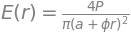

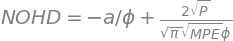

Units: P [W], a [cm], phi [rad], MPE [W/cm^2] -> NOHD [cm]; OD is dimensionless (a log10).


E_MPE at t = 1/4 s: 9*sqrt(2)/5000 = 0.002546 W/cm^2


In [3]:
P, r, a, phi, MPE, Ex, OD = sp.symbols("P r a phi MPE E OD", positive=True)
E_r = 4 * P / (sp.pi * (a + r * phi)**2)
display(sp.Eq(sp.Symbol("E(r)"), E_r))
nohd_sym = [s for s in sp.solve(sp.Eq(E_r, MPE), r) if s.has(sp.sqrt(P))]
display(sp.Eq(sp.Symbol("NOHD"), sp.simplify(nohd_sym[0])))

od_eq = sp.Eq(MPE, Ex * 10**(-OD))                 # eyewear passes 10^-OD of the light
display(od_eq, sp.Eq(OD, sp.solve(od_eq, OD)[0]))
print("Units: P [W], a [cm], phi [rad], MPE [W/cm^2] -> NOHD [cm]; OD is dimensionless (a log10).")

t = sp.Symbol("t", positive=True)
H = sp.Rational(18, 10) * sp.Rational(1, 1000) * t**sp.Rational(3, 4)   # J/cm^2
display(sp.Eq(sp.Symbol("H_MPE"), H), sp.Eq(sp.Symbol("E_MPE"), sp.simplify(H / t)))
print("E_MPE at t = 1/4 s:", sp.nsimplify(H / t).subs(t, sp.Rational(1, 4)), "=", sp.N((H / t).subs(t, sp.Rational(1, 4)), 4), "W/cm^2")

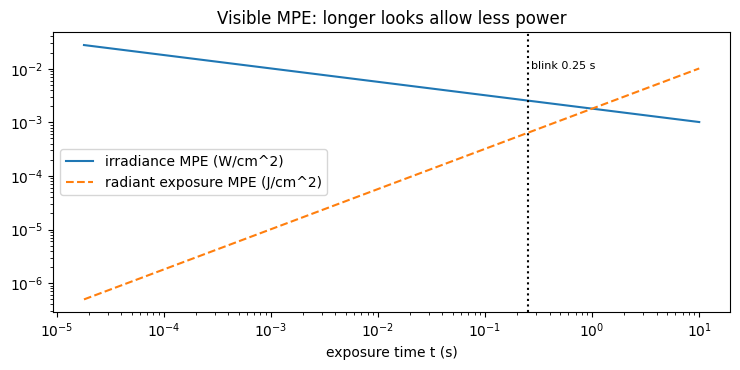

In [4]:
ts = np.logspace(np.log10(1.8e-5), 1, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.loglog(ts, [S.mpe_visible(x) for x in ts], label="irradiance MPE (W/cm^2)")
ax.loglog(ts, [S.mpe_visible(x) * x for x in ts], "--", label="radiant exposure MPE (J/cm^2)")
ax.axvline(0.25, color="k", ls=":"); ax.text(0.27, 1e-2, "blink 0.25 s", fontsize=8)
ax.set_xlabel("exposure time t (s)"); ax.legend(); ax.set_title("Visible MPE: longer looks allow less power")
plt.tight_layout(); plt.show()

## 3. Public safety: laser pointers

Typical pointer beam: exit diameter a = 1 mm, divergence φ = 1 mrad (assumptions).
US consumer laser pointers are limited to 5 mW (FDA). Higher-power "pointers" are sold
online anyway.

,power,NOHD (m),OD needed at the aperture
0,1 mW,6.07,1.7
1,5 mW,14.81,2.4
2,100 mW,69.72,3.7
3,1000 mW,222.65,4.7


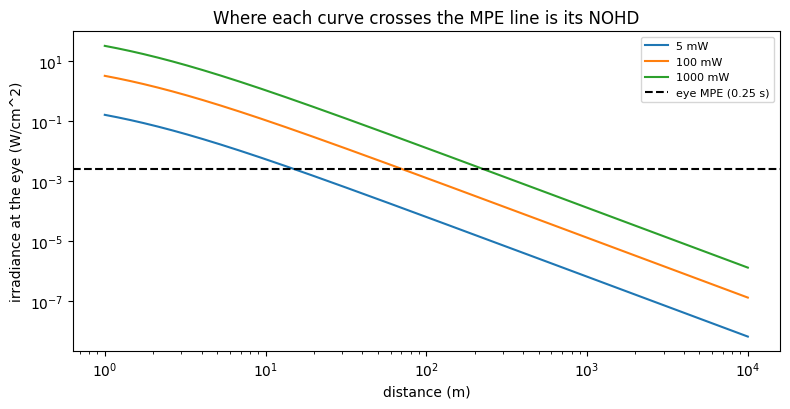

In [5]:
a_cm, phi_rad = 0.1, 1e-3
rows = []
for P_w in (1e-3, 5e-3, 100e-3, 1.0):
    d_hazard = S.nohd(P_w, MPE_BLINK, a_cm, phi_rad) / 100
    rows.append((f"{P_w * 1e3:g} mW", d_hazard, S.required_od(float(S.irradiance(P_w, 0, a_cm, phi_rad)), MPE_BLINK)))
display(pd.DataFrame(rows, columns=["power", "NOHD (m)", "OD needed at the aperture"]).round(2))

r_m = np.logspace(0, 4, 400)
fig, ax = plt.subplots(figsize=(8, 4.2))
for P_w in (5e-3, 100e-3, 1.0):
    ax.loglog(r_m, S.irradiance(P_w, r_m * 100, a_cm, phi_rad), label=f"{P_w * 1e3:g} mW")
ax.axhline(MPE_BLINK, color="k", ls="--", label="eye MPE (0.25 s)")
ax.set_xlabel("distance (m)"); ax.set_ylabel("irradiance at the eye (W/cm^2)"); ax.legend(fontsize=8)
ax.set_title("Where each curve crosses the MPE line is its NOHD")
plt.tight_layout(); plt.show()

Eye injury is not the only aviation hazard. Glare and flash blindness at much lower
irradiance can still blind a pilot during landing, so aviation rules also set *visual
interference* limits far below the MPE. Look those up in the current FAA guidance instead of
trusting a number from memory. To find the distance for any limit, call
`S.nohd(P, limit, a, phi)` with that limit in place of the MPE.

## 4. The eyewear simulator

Scenario: a lab beam hits the eye at distance r through eyewear of optical density OD.
Change the inputs in the next cell and re-run. The output gives the required OD, the exposure
behind the eyewear, and the safety margin (MPE ÷ exposure; above 1 means below the MPE).

,eyewear OD,OD required,exposure behind (W/cm^2),margin,result
0,0,3.74488,14.147106,0.000180,ABOVE MPE
1,2,3.74488,0.141471,0.017994,ABOVE MPE
2,3,3.74488,0.014147,0.179937,ABOVE MPE
3,4,3.74488,0.001415,1.799368,below MPE
4,5,3.74488,0.000141,17.993676,below MPE
5,6,3.74488,0.000014,179.936759,below MPE


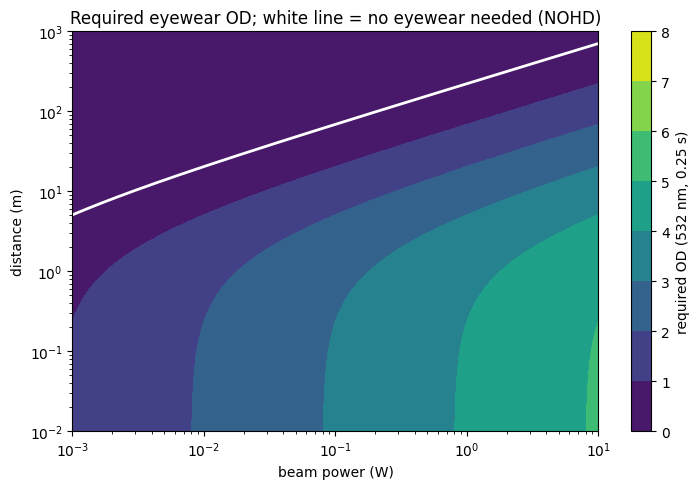

In [6]:
# ---- scenario inputs (edit) ----
POWER_W, LAMBDA_NM, DIST_CM, A_CM, PHI_RAD = 1.0, 532, 100, 0.2, 1e-3
rows = []
for od in (0, 2, 3, 4, 5, 6):
    c = S.eyewear_check(POWER_W, LAMBDA_NM, DIST_CM, A_CM, PHI_RAD, od)
    rows.append((od, c["OD_required"], c["E_behind_W_cm2"], c["margin"], "below MPE" if c["below_MPE"] else "ABOVE MPE"))
display(pd.DataFrame(rows, columns=["eyewear OD", "OD required", "exposure behind (W/cm^2)", "margin", "result"]))

powers = np.logspace(-3, 1, 200); dists = np.logspace(0, 5, 200)
Pg, Dg = np.meshgrid(powers, dists)
ODreq = np.log10(np.maximum(S.irradiance(Pg, Dg, A_CM, PHI_RAD) / MPE_BLINK, 1.0))
fig, ax = plt.subplots(figsize=(7.5, 5))
cs = ax.contourf(Pg, Dg / 100, ODreq, levels=np.arange(0, 8.5, 1), cmap="viridis")
ax.plot(powers, [S.nohd(p, MPE_BLINK, A_CM, PHI_RAD) / 100 for p in powers], "w", lw=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("beam power (W)"); ax.set_ylabel("distance (m)")
fig.colorbar(cs, label="required OD (532 nm, 0.25 s)")
ax.set_title("Required eyewear OD; white line = no eyewear needed (NOHD)")
plt.tight_layout(); plt.show()

## Practice (my own problems)

1. A 20 mW, 532 nm beam has a = 1.5 mm and φ = 1.2 mrad. Find the NOHD.
2. What OD is needed to look into a 2 W beam (2 mm diameter, at the aperture) for 0.25 s?
3. OD 4 eyewear is rated for a 10 W beam at 1 m (a = 2 mm, φ = 1 mrad). Is the exposure behind it below the MPE?
4. By what factor does the NOHD grow when the power goes up 100×, ignoring a?

In [7]:
print(f"1. NOHD = {S.nohd(20e-3, MPE_BLINK, 0.15, 1.2e-3) / 100:.1f} m")
print(f"2. OD = {S.required_od(float(S.irradiance(2.0, 0, 0.2, 1e-3)), MPE_BLINK):.2f} -> buy OD >= {math.ceil(S.required_od(float(S.irradiance(2.0, 0, 0.2, 1e-3)), MPE_BLINK))}")
c = S.eyewear_check(10.0, 532, 100, 0.2, 1e-3, od=4)
print(f"3. needs OD {c['OD_required']:.2f}; OD 4 -> {'below' if c['below_MPE'] else 'ABOVE'} MPE (margin {c['margin']:.2f})")
print("4. NOHD ~ sqrt(P), so 100x power -> 10x distance")

1. NOHD = 25.1 m
2. OD = 4.40 -> buy OD >= 5
3. needs OD 4.74; OD 4 -> ABOVE MPE (margin 0.18)
4. NOHD ~ sqrt(P), so 100x power -> 10x distance


## Checklist

- [ ] E(r) = 4P/(π(a + rφ)²). The beam spreads, so the hazard falls with distance.
- [ ] Visible MPE: H = 1.8·t^0.75 mJ/cm², about 2.5 mW/cm² at the 0.25 s blink time.
- [ ] NOHD = (√(4P/(π·MPE)) − a)/φ, and it scales as √P.
- [ ] OD = log₁₀(E/MPE), transmission = 10^(−OD). Round the OD up, never down.
- [ ] For a real lab: the current standard and your institution's Laser Safety Officer.